# Example 7.1 — Hybrid Lamarckian GA for Four-Bar Synthesis

**Chapter 7: Hybrid and Advanced Strategies**

It compares the standard GA with a hybrid Lamarckian GA that refines each individual with local search (hill-climbing) before evaluating its fitness.

**Book Reference:** Section 7.1 — Hybrid GA for Mechanism Synthesis

In [14]:
import numpy as np
import builtins

# ── Fixed mechanism parameters ──────────────────────────────────────
D_TARGET = 50.0   # Length (mm) of the input link
THETA2_RANGE = np.linspace(0, 2 * np.pi, 60)  # Crank rotation range

# ── Trajectory error function ───────────────────────────────────
def trayectoria(a, b, c, d=50.0):
    """Calculates the (x, y) points of the coupler link end."""
    pts = []
    for t2 in THETA2_RANGE:
        K1 = d / a
        K2 = d / c
        K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

        A = np.cos(t2) - K1 - K2 * np.cos(t2) + K3
        B = -2 * np.sin(t2)
        C = K1 - (K2 + 1) * np.cos(t2) + K3

        disc = B**2 - 4 * A * C
        if disc < 0 or abs(A) < 1e-9:
            continue

        t4 = 2 * np.arctan((-B - np.sqrt(disc)) / (2 * A))
        t3_num = a * np.sin(t2) - c * np.sin(t4)
        t3_den = a * np.cos(t2) + d - c * np.cos(t4)
        t3 = np.arctan2(t3_num, t3_den)

        x = a * np.cos(t2) + b * np.cos(t3)
        y = a * np.sin(t2) + b * np.sin(t3)
        pts.append((x, y))

    return np.array(pts) if pts else np.zeros((1, 2))

def hausdorff(P, Q):
    """Discrete Hausdorff distance between two trajectories."""
    if len(P) < 2 or len(Q) < 2:
        return 1e6
    n = builtins.min(len(P), len(Q))
    P, Q = P[:n], Q[:n]

    # Calculate pairwise Euclidean distances
    diff = P[:, np.newaxis, :] - Q[np.newaxis, :, :]
    dist_matrix = np.sqrt(np.sum(diff**2, axis=-1))

    d1 = np.max(np.min(dist_matrix, axis=1))
    d2 = np.max(np.min(dist_matrix, axis=0))
    return builtins.max(d1, d2)

# Target trajectory: 40×20 mm ellipse
TARGET = np.column_stack([40 * np.cos(THETA2_RANGE), 20 * np.sin(THETA2_RANGE)])

def fitness(ind):
    """Fitness function based on the Hausdorff distance."""
    a, b, c = ind
    if a <= 0 or b <= 0 or c <= 0:
        return 1e6
    P = trayectoria(a, b, c)
    return hausdorff(P, TARGET)

In [15]:
# ── Standard GA ────────────────────────────────────────────────────────
def ga_estandar(seed=42, n_pop=15, n_gen=25, lb=10, ub=100):
    import numpy as np
    np.random.seed(seed)
    pop = np.random.uniform(lb, ub, (n_pop, 3))
    hist = []

    for gen in range(n_gen):
        fit = np.array([fitness(ind) for ind in pop])
        best = fit.min()
        hist.append(best)

        # Tournament selection
        new_pop = []
        for _ in range(n_pop):
            i1, i2 = np.random.choice(n_pop, 2, replace=False)
            winner = pop[i1] if fit[i1] < fit[i2] else pop[i2]
            new_pop.append(winner.copy())
        new_pop = np.array(new_pop)

        # BLX-0.5 crossover
        for k in range(0, n_pop - 1, 2):
            alpha = np.random.uniform(-0.5, 1.5, 3)
            child = new_pop[k] + alpha * (new_pop[k+1] - new_pop[k])
            new_pop[k] = np.clip(child, lb, ub)

        # Gaussian mutation
        mask = np.random.random((n_pop, 3)) < 0.15
        new_pop += mask * np.random.normal(0, 5, (n_pop, 3))
        pop = np.clip(new_pop, lb, ub)

    fit = np.array([fitness(ind) for ind in pop])
    return hist, pop[fit.argmin()]

hist_std, best_std = ga_estandar()
print(f'Standard GA → initial: {hist_std[0]:.2f} mm | final: {hist_std[-1]:.2f} mm')

Standard GA → initial: 49.43 mm | final: 35.98 mm


In [16]:
# ── Hybrid Lamarckian GA ─────────────────────────────────────────────
def hill_climb(ind, lb=10, ub=100, steps=10, sigma=2.0):
    """Local refinement (Gaussian hill-climbing)."""
    best = ind.copy()
    bf = fitness(ind)

    for _ in range(steps):
        candidate = np.clip(best + np.random.normal(0, sigma, 3), lb, ub)
        cf = fitness(candidate)
        if cf < bf:
            best = candidate
            bf = cf
    return best

def ga_hibrido(seed=42, n_pop=15, n_gen=25, lb=10, ub=100):
    import numpy as np
    np.random.seed(seed)
    pop = np.random.uniform(lb, ub, (n_pop, 3))
    hist = []

    for gen in range(n_gen):
        # Lamarckian refinement: local in-situ improvement
        pop = np.array([hill_climb(ind) for ind in pop])
        fit = np.array([fitness(ind) for ind in pop])
        hist.append(fit.min())

        # Selection, crossover, and mutation (same as standard GA)
        new_pop = []
        for _ in range(n_pop):
            i1, i2 = np.random.choice(n_pop, 2, replace=False)
            winner = pop[i1] if fit[i1] < fit[i2] else pop[i2]
            new_pop.append(winner.copy())
        new_pop = np.array(new_pop)

        for k in range(0, n_pop - 1, 2):
            alpha = np.random.uniform(-0.5, 1.5, 3)
            child = new_pop[k] + alpha * (new_pop[k+1] - new_pop[k])
            new_pop[k] = np.clip(child, lb, ub)

        mask = np.random.random((n_pop, 3)) < 0.15
        new_pop += mask * np.random.normal(0, 5, (n_pop, 3))
        pop = np.clip(new_pop, lb, ub)

    fit = np.array([fitness(ind) for ind in pop])
    return hist, pop[fit.argmin()]

hist_hyb, best_hyb = ga_hibrido()
print(f'Hybrid GA    → initial: {hist_hyb[0]:.2f} mm | final: {hist_hyb[-1]:.2f} mm')

mejora = (hist_std[-1] - hist_hyb[-1]) / hist_std[-1] * 100
print(f'Improvement of Hybrid vs. Standard: {mejora:.1f}%')

Hybrid GA    → initial: 42.11 mm | final: 9.97 mm
Improvement of Hybrid vs. Standard: 72.3%


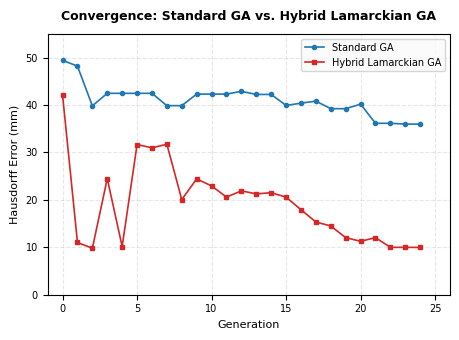


Best solutions found:
  Standard GA: a=35.0, b=30.9, c=55.9
  Hybrid GA:   a=10.0, b=40.4, c=100.0


In [18]:
# ── Convergence plot (Springer Publication Standards) ────────────────────────────────
import os
import glob
import matplotlib.pyplot as plt

# 1. Automated Filename System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_7_1_lamarckian_hybrid_ga"
except Exception:
    notebook_name = "Figure_7_1_lamarckian_hybrid_ga"

# 2. Springer Plot Configuration
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

# Springer single-column standard is ~3.15 to 4.7 inches wide
fig, ax = plt.subplots(figsize=(4.7, 3.5))

# Clean, high-contrast publication styling
ax.plot(hist_std, color='#1f77b4', linestyle='-', marker='o', markersize=3,
        linewidth=1.2, label='Standard GA')
ax.plot(hist_hyb, color='#d62728', linestyle='-', marker='s', markersize=3,
        linewidth=1.2, label='Hybrid Lamarckian GA')

# Academic English annotations and labels
ax.set_xlabel('Generation', fontsize=8)
ax.set_ylabel('Hausdorff Error (mm)', fontsize=8)
ax.set_title('Convergence: Standard GA vs. Hybrid Lamarckian GA', fontsize=9, fontweight='bold', pad=10)

# Avoid overlaps by increasing axis limits gracefully
ax.set_ylim(0, 55)
ax.set_xlim(-1, 26)

# Discrete grid and minimalist legend
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper right', fontsize=7, frameon=True, edgecolor='#cccccc', facecolor='#fafafa')
ax.tick_params(axis='both', which='major', labelsize=7)

# 3. Double Export and Display
plt.tight_layout()
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print('\nBest solutions found:')
print(f'  Standard GA: a={best_std[0]:.1f}, b={best_std[1]:.1f}, c={best_std[2]:.1f}')
print(f'  Hybrid GA:   a={best_hyb[0]:.1f}, b={best_hyb[1]:.1f}, c={best_hyb[2]:.1f}')